In [260]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from scipy.interpolate import Akima1DInterpolator
import numpy as np


mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [261]:
def _rolling_median_mad(arr, window):
    """Return rolling median and robust scale (1.4826*MAD) per channel."""
    df = pd.DataFrame(arr)
    med = df.rolling(window, center=True, min_periods=1).median()
    mad = (df - med).abs().rolling(window, center=True, min_periods=1).median()
    scale = 1.4826 * mad.clip(lower=1e-6)
    return med.to_numpy(), scale.to_numpy()

def _keep_narrow_runs(mask_col, max_len):
    """Keep only True-runs whose length <= max_len."""
    out = np.zeros_like(mask_col, dtype=bool)
    idx = np.flatnonzero(mask_col)
    if idx.size == 0:
        return out
    cuts = np.where(np.diff(idx) > 1)[0]
    starts = np.r_[idx[0], idx[cuts + 1]]
    ends = np.r_[idx[cuts], idx[-1]]
    lens = ends - starts + 1
    for s, e, l in zip(starts, ends, lens):
        if l <= max_len:
            out[s:e+1] = True
    return out

def _dilate_mask(mask, r=1):
    """Binary dilation by ±r samples per channel."""
    if r <= 0:
        return mask
    T, C = mask.shape
    out = np.zeros_like(mask)
    kern = np.ones(2*r + 1, dtype=int)
    for c in range(C):
        conv = np.convolve(mask[:, c].astype(int), kern, mode='same')
        out[:, c] = conv > 0
    return out

def despike_impulsive_dips(channels, fs=30, window=11, k=3.5, sharp_sigma=2.0, quorum=0.6, max_len=3, dilate=1):
    x = np.asarray(channels, dtype=float)
    T, C = x.shape

    # 1) Robust local baseline + scale
    med, scale = _rolling_median_mad(x, window)

    # 2) Negative outliers by magnitude
    mag_mask = (x - med) < (-k * scale)

    # 3) Sharpness: V-shape (steep drop then rise) OR very narrow runs
    dx_prev = x - np.vstack([x[0:1, :], x[:-1, :]])
    dx_next = np.vstack([x[1:, :], x[-1:, :]]) - x
    sharp_mask = (dx_prev < -(sharp_sigma * scale)) & (dx_next > (sharp_sigma * scale))

    # Narrow_run mask per channel (<= max_len)
    narrow_mask = np.zeros_like(mag_mask, dtype=bool)
    for c in range(C):
        narrow_mask[:, c] = _keep_narrow_runs(mag_mask[:, c], max_len=max_len)
    
    cand = mag_mask & (sharp_mask | narrow_mask)

    # 4) Conservative dilation to capture edges
    cand = _dilate_mask(cand, r=dilate)

    # 5) Multi-channel quorum: requre co-occurrence across channels
    q = int(np.ceil(quorum * C))
    time_ok = (cand.sum(axis=1) >= q)
    mask = cand & time_ok[:, None]

    # 6) Short-gap inpainting
    t = np.arange(T)
    y = x.copy()
    for c in range(C):
        m = mask[:, c]
        if not np.any(m):
            continue
        keep = ~m

        if keep.sum() < 2:
            continue
        try:
            interpolator = Akima1DInterpolator(t[keep], y[keep, c])
            y[m, c] = interpolator(t[m])
        except Exception as e:
            print(f'Error: {e}, fall back to linear interp.')
            y[m, c] = np.interp(t[m], t[keep], y[keep, c])
    return y

In [293]:
data = pd.read_csv('../data/BTVIZ_2025-04-02.csv')
data.head()

C:\Users\y1hli\AppData\Local\Temp\ipykernel_21188\4079054614.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('../data/BTVIZ_2025-04-02.csv')


,id,timestamp,notificationTimestamp,deviceName,data_0,data_1,data_2,data_3,data_4,data_5
0,2025-04-02T13:58:02.657Z,1743602282657,28,NaN,1.0,2.0,5.0,6.0,6.0,4.0
1,2025-04-02T13:58:02.657Z,1743602282657,88,NaN,1.0,2.0,5.0,6.0,6.0,4.0
2,2025-04-02T13:58:02.657Z,1743602282657,88,NaN,1.0,2.0,5.0,6.0,6.0,4.0
3,2025-04-02T13:58:02.657Z,1743602282657,88,NaN,1.0,2.0,5.0,6.0,6.0,4.0
4,2025-04-02T13:58:02.657Z,1743602282657,106,NaN,1.0,2.0,5.0,6.0,6.0,4.0


In [322]:
timestamp = data.index.to_series().to_numpy()

channels = data.iloc[:, data.columns.str.startswith('data_')]
channels = channels.to_numpy()
sos1 = butter(4, 5, 'lowpass', fs=30, output='sos')
channels_f = sosfiltfilt(sos1, channels, axis=0)

channels_c = despike_impulsive_dips(
    channels_f,
    window=5,
    k=2.0,
    sharp_sigma=1.0,
    max_len=3,
    dilate=2,
    quorum=0.5,    
)

sos2 = butter(4, (0.2, 1.8), 'bandpass', fs=30, output='sos')
channels_f = sosfiltfilt(sos2, channels_c, axis=0)

# sos21 = butter(4, 0.2, 'highpass', fs=30, output='sos')
# channels_cf = sosfiltfilt(sos21, channels_c, axis=0)

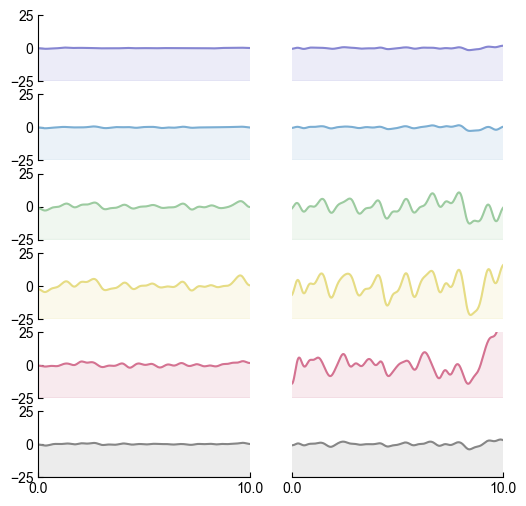

In [327]:
t1 = 2400
t2 = 3.8917e5
d = 300

time_limits_1 = (t1, t1 + d)
time_limits_2 = (t2, t2 + d)

amplitude_limits = (-25, 25)

fig, axes = plt.subplots(nrows=6, ncols=2, figsize=(6, 6))

sample_rate = 30.0

# Left column - first time region
for i, ax in enumerate(axes[:, 0]):
    y = channels_f[:, i]
    ax.plot(timestamp, y, color=colors[i], alpha=1)
    ax.fill_between(timestamp, y, amplitude_limits[0] * np.ones_like(y), color=colors[i], alpha=0.15)
    ax.set_xlim(*time_limits_1)
    ax.set_ylim(-25, 25)

    x_ticks = np.linspace(time_limits_1[0], time_limits_1[1], 2)
    x_labels = [f'{(x - time_limits_1[0]) / sample_rate:.1f}' for x in x_ticks]
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels if i == 5 else [])
    
    ax.tick_params(axis='both', which='both', direction='in')
    if i < 5:
        ax.tick_params(axis='x', which='both', length=0, direction='in')
    ax.tick_params(axis='y', which='both', direction='in', labelleft=True)

    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(i == 5)
    ax.spines['left'].set_visible(True)
    ax.spines['right'].set_visible(False)

# Right column - second time region
for i, ax in enumerate(axes[:, 1]):
    y = channels_f[:, i]
    ax.plot(timestamp, y, color=colors[i], alpha=1)
    ax.fill_between(timestamp, y, amplitude_limits[0] * np.ones_like(y), color=colors[i], alpha=0.15)
    ax.set_xlim(*time_limits_2)
    ax.set_ylim(-25, 25)

    x_ticks = np.linspace(time_limits_2[0], time_limits_2[1], 2)
    x_labels = [f'{(x - time_limits_2[0]) / sample_rate:.1f}' for x in x_ticks]
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels if i == 5 else [])
    
    ax.tick_params(axis='both', which='both', direction='in')
    if i < 5:
        ax.tick_params(axis='x', which='both', length=0, direction='in')
    
    ax.set_yticks([])

    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(i == 5)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
